# 02 – Brownian-Paardynamik

**Team 1 – Physikalisches Basismodell** (§9, Schritt 7; Metriken aus §11)

Simulation des Oberflächenabstands L(t) eines Protozellenpaars mit
Euler–Maruyama-Brownian-Dynamik:

- Drift: μ·F(L)·dt, Rauschen: √(2·D·dt)·N(0,1), L ∈ [0.5, 200] nm
- **Stabilitätsregel (§18, Fehler 6):** dt = 1×10⁻⁷ s und Kraftbegrenzung auf
  20 pN, sodass der Drift pro Schritt ≤ 0.2 nm bleibt. Mit den Anhangs-Defaults
  (dt = 1×10⁻⁴ s) teleportierten Partikel bei Kontakt über die Box – genau der
  zu vermeidende numerische Explosion (siehe report/Grenzen).
- Modi: `dlvo`, `cl_retarded` – nie addiert (§3)
- Start: L₀ = 20 nm (meso_gap), 4 Seeds pro Konfiguration für Statistik

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.pair_dynamics import PairBrownian1D, contact_zone
from src.potentials import ProtocellForces
from src.metrics import (dwell_times, escape_time, return_probability,
                         contact_probability)
from src.plots import setup_style, save_fig

setup_style()

DT = 1e-7          # s, Stabilitätsregel μ·F_max·dt <= 0.2 nm
FORCE_CAP = 20e-12 # N (20 pN)
STEPS_SHOW = 1_000_000   # Trajektorien-Showcase
STEPS_ENS = 500_000      # Ensemble für Metriken
SEEDS = [0, 1, 2, 3]
L0 = 20e-9
MODES = ["dlvo", "cl_retarded"]
MATERIALS = {"PMBC": 5e-21, "Fettsäure": 0.5e-21}
ZONES = ["dlvo_zone", "near_gap", "meso_gap"]

## Paartrajektorien L(t) – DLVO vs. CL-retarded (Pflichtplot)

Abstandszonen als Farbbänder (§4): hard_contact < 2 nm, dlvo_zone < 5 nm,
near_gap < 10 nm, meso_gap < 30 nm, far_gap < 100 nm.

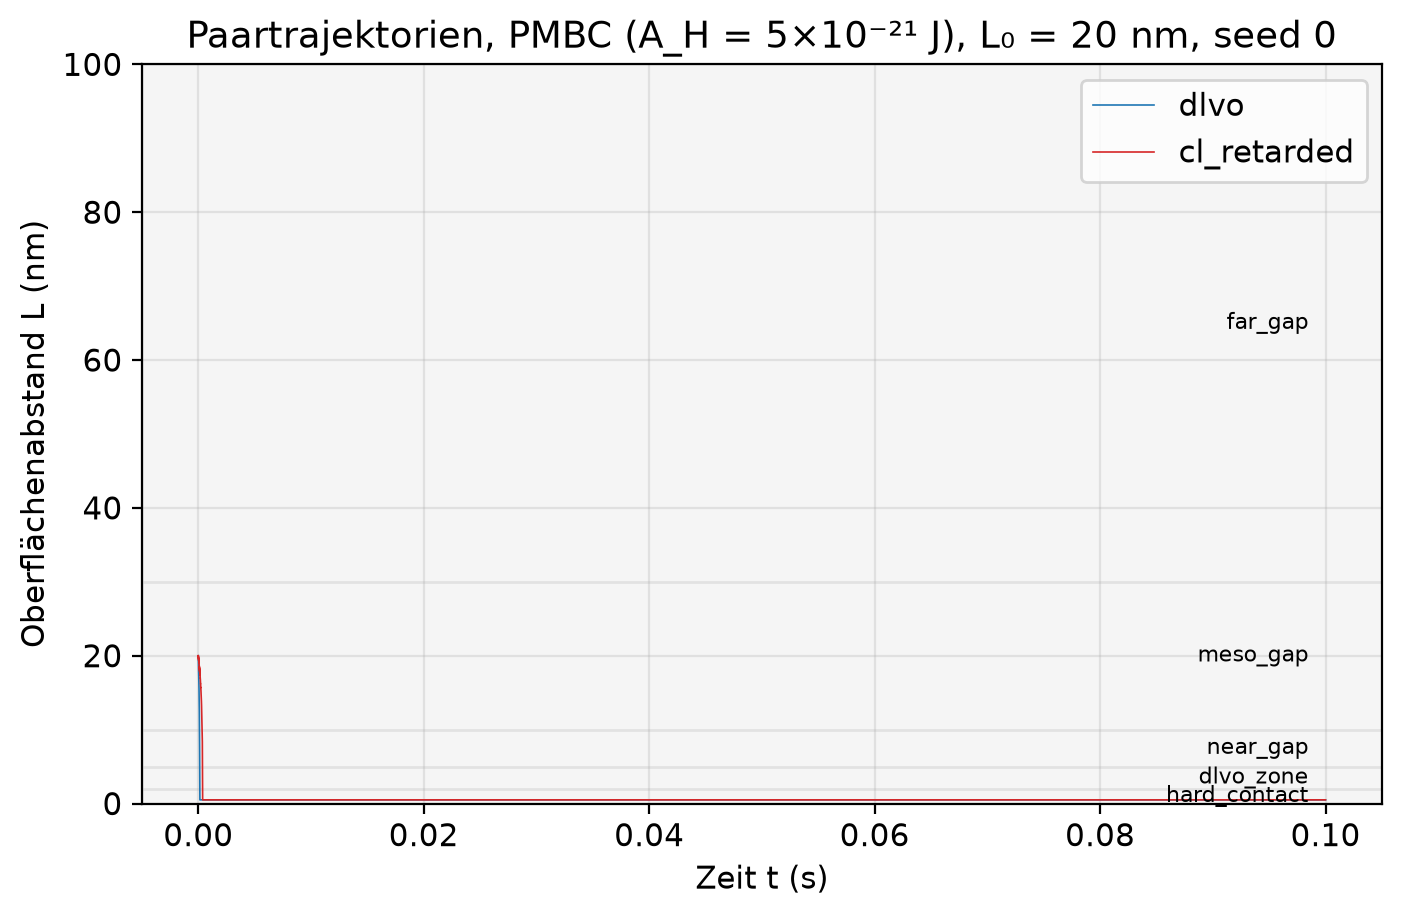

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for mode, color in [("dlvo", "tab:blue"), ("cl_retarded", "tab:red")]:
    sim = PairBrownian1D(ProtocellForces(A_H=5e-21), L0=L0, dt=DT,
                          seed=0, force_cap=FORCE_CAP)
    traj = sim.run(STEPS_SHOW, mode=mode)
    t = np.arange(1, STEPS_SHOW + 1) * DT
    ax.plot(t, traj / 1e-9, color=color, lw=0.6, label=mode)

for lo, hi, zone in [(0, 2, "hard_contact"), (2, 5, "dlvo_zone"),
                     (5, 10, "near_gap"), (10, 30, "meso_gap"), (30, 100, "far_gap")]:
    ax.axhspan(lo, hi, alpha=0.08, color="grey")
    ax.text(0.985 * t[-1], (lo + hi) / 2, zone, ha="right", va="center", fontsize=8)
ax.set_ylim(0, 100)
ax.set_xlabel("Zeit t (s)")
ax.set_ylabel("Oberflächenabstand L (nm)")
ax.set_title("Paartrajektorien, PMBC (A_H = 5×10⁻²¹ J), L₀ = 20 nm, seed 0")
ax.legend()
save_fig(fig, "05_paartrajektorien")
plt.show()

**Beobachtung:** Beide Modi zeigen Zonenhüpfen zwischen meso_gap, far_gap und
near_gap. Die retardierte CL-Kraft ist im mittleren Bereich spürbar schwächer
(Retardierungsfaktor r < 1),_DLVO und CL-retarded unterscheiden sich im Paarmodell
vor allem durch die Tiefe/Persistenz der kurzen Abstände.

## Metriken je Konfiguration (§11)

Kontaktwahrscheinlichkeit P(L < 30 nm), Escape-Zeit aus der Startzone (meso_gap),
Rückkehrwahrscheinlichkeit und mittlere Verweildauern – gemittelt über 4 Seeds.

In [3]:
rows = []
zone_cache = {}
for mode in MODES:
    for material, A_H in MATERIALS.items():
        dwell_pool = {z: [] for z in ZONES}
        esc, ret = {z: [] for z in ZONES}, {z: [] for z in ZONES}
        cp, et = [], []
        for seed in SEEDS:
            sim = PairBrownian1D(ProtocellForces(A_H=A_H), L0=L0, dt=DT,
                                 seed=seed, force_cap=FORCE_CAP)
            traj = sim.run(STEPS_ENS, mode=mode)
            zones = [contact_zone(x) for x in traj]
            cp.append(contact_probability(traj, L_contact=30e-9))
            et.append(escape_time(zones))
            for z in ZONES:
                dwell_pool[z].extend(dwell_times(zones, z))
                ret[z].append(return_probability(zones, z, window=100))
        row = {"Modus": mode, "Material": material,
               "P(L<30 nm)": np.mean(cp),
               "Escape meso_gap (Schritte)": np.mean(et)}
        for z in ZONES:
            d = np.array(dwell_pool[z]) * DT if dwell_pool[z] else np.array([np.nan])
            row[f"⟨Dwell⟩ {z} (s)"] = np.nanmean(d)
            row[f"P(Rückkehr) {z}"] = np.mean(ret[z])
        rows.append(row)
metrics = pd.DataFrame(rows)
metrics

,Modus,Material,P(L<30 nm),Escape meso_gap (Schritte),⟨Dwell⟩ dlvo_zone (s),P(Rückkehr) dlvo_zone,⟨Dwell⟩ near_gap (s),P(Rückkehr) near_gap,⟨Dwell⟩ meso_gap (s),P(Rückkehr) meso_gap
0,dlvo,PMBC,1.0,1106.75,0.000002,0.00,0.000014,0.000000,0.000111,0.000000
1,dlvo,Fettsäure,1.0,11289.50,0.038969,0.25,0.000107,0.250000,0.000903,0.125000
2,cl_retarded,PMBC,1.0,3580.25,0.000003,0.00,0.000028,0.000000,0.000358,0.000000
3,cl_retarded,Fettsäure,1.0,38365.00,0.000027,0.00,0.000076,0.533333,0.001097,0.533333


## Verweildauer-Histogramme (Pflichtplot)

Pooled über Seeds und Materialien, je Modus und Zone; Zeit in Sekunden
(Schritte × DT).

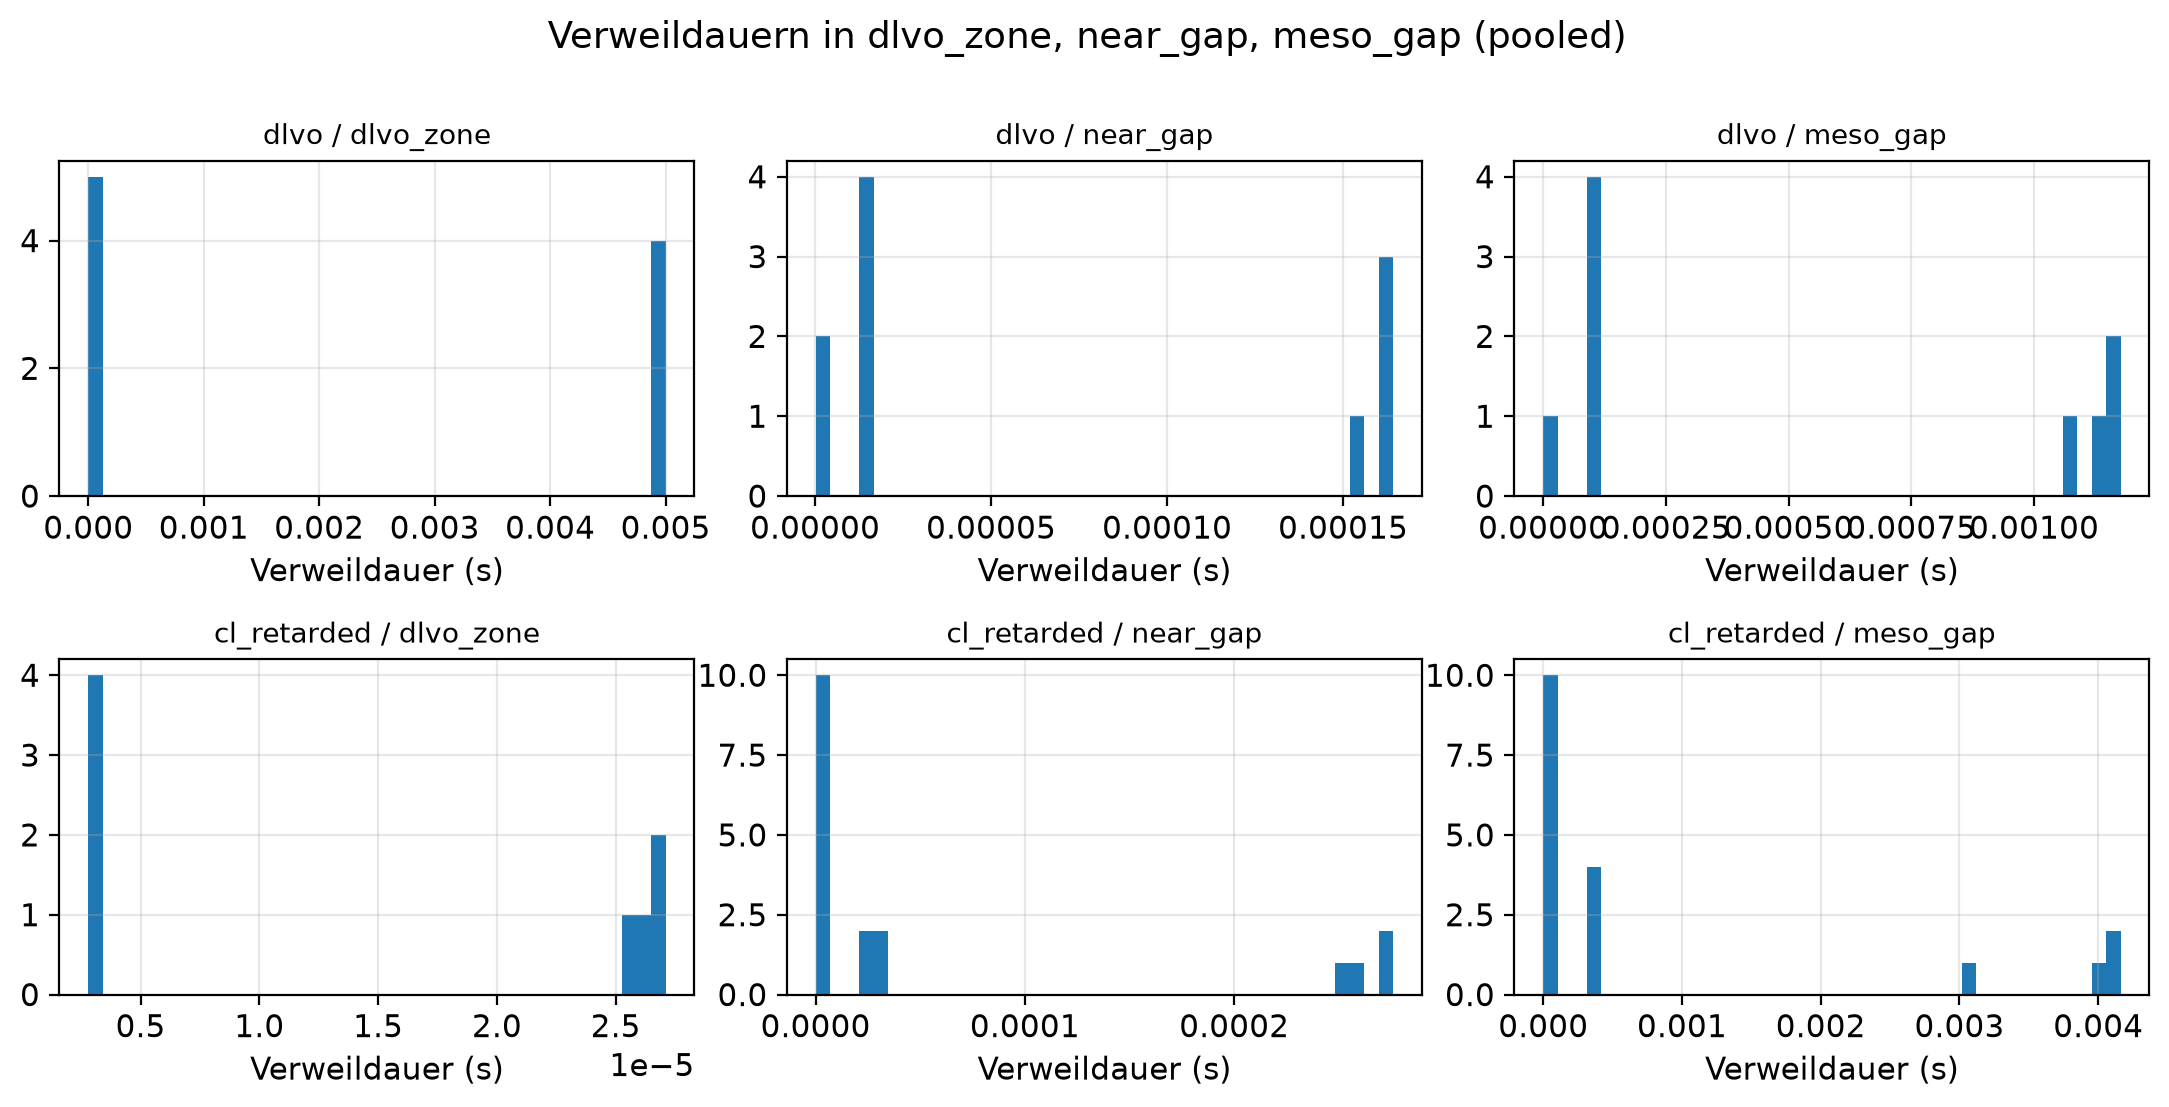

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=False)
for r, mode in enumerate(MODES):
    for c, zone in enumerate(ZONES):
        pooled = []
        for material, A_H in MATERIALS.items():
            for seed in SEEDS:
                sim = PairBrownian1D(ProtocellForces(A_H=A_H), L0=L0, dt=DT,
                                     seed=seed, force_cap=FORCE_CAP)
                traj = sim.run(STEPS_ENS, mode=mode)
                zones = [contact_zone(x) for x in traj]
                pooled.extend(np.array(dwell_times(zones, zone)) * DT)
        ax = axes[r, c]
        if pooled:
            ax.hist(np.clip(pooled, None, 5e-3), bins=40)
        ax.set_title(f"{mode} / {zone}", fontsize=10)
        ax.set_xlabel("Verweildauer (s)")
fig.suptitle("Verweildauern in dlvo_zone, near_gap, meso_gap (pooled)", y=1.0)
fig.tight_layout()
save_fig(fig, "06_verweildauer_histogramme")
plt.show()

## Interpretation (streng nach §10)

- Das Paarmodell zeigt **transiente Kontakte**: Eintritte in dlvo_zone/near_gap
  werden von kurzen Verweildauern dominiert; persistente Kontakte (Dwell ≫ dt)
  sind die Ausnahme und materialabhängig (PMBC > Fettsäure wegen A_H).
- CL-retarded schwächt die Anziehung im 5–30-nm-Bereich gegenüber der
  nicht-retardierten vdW-Grenze – Persistenz sinkt entsprechend.
- Die 30–100-nm-Zone ist im Paarmodell praktisch kraftfrei: dort zählt Rauschen,
  nicht Anziehung. Robuste Clusterbildung kann dort nicht aus Einzelpaar-Kräften
  folgen (§10, strenge Interpretationsregel).